In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [12]:
df = pd.read_csv("D:\\Data science\\codes\\files\\AR_DATA.csv")
df

,0
0,0.496714
1,0.110093
2,0.702735
3,1.874397
4,0.703045
...,...
195,0.197749
196,-0.784983
197,-0.238766
198,-0.061174


### SMS

<Axes: >

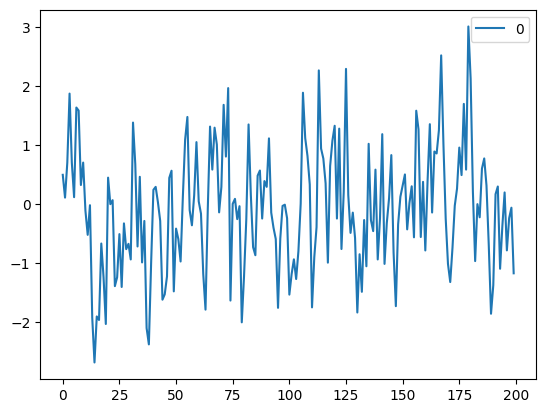

In [14]:
df.plot()

In [15]:
model = SimpleExpSmoothing(df['0'])
# model_fitted = model.fit(smoothing_level=0.2, optimized=False) #---> to give alfa manually
model_fitted = model.fit(optimized=True) #--->auto chooses the alfa value/smooth value to reduse mse or rmse


In [16]:
rmse = np.sqrt(np.mean(model_fitted.resid**2))
display(rmse)

1.002553549784215

In [17]:
# next 5 periods ==> h = 5
forecast = model_fitted.forecast(steps = 5)
print("Fitted value: ", model_fitted.fittedvalues)
print("Forecasted values:", forecast)

Fitted value:  0      0.496714
1      0.496714
2      0.385145
3      0.476793
4      0.880105
         ...   
195   -0.459336
196   -0.269719
197   -0.418410
198   -0.366570
199   -0.278441
Length: 200, dtype: float64
Forecasted values: 200   -0.536748
201   -0.536748
202   -0.536748
203   -0.536748
204   -0.536748
dtype: float64


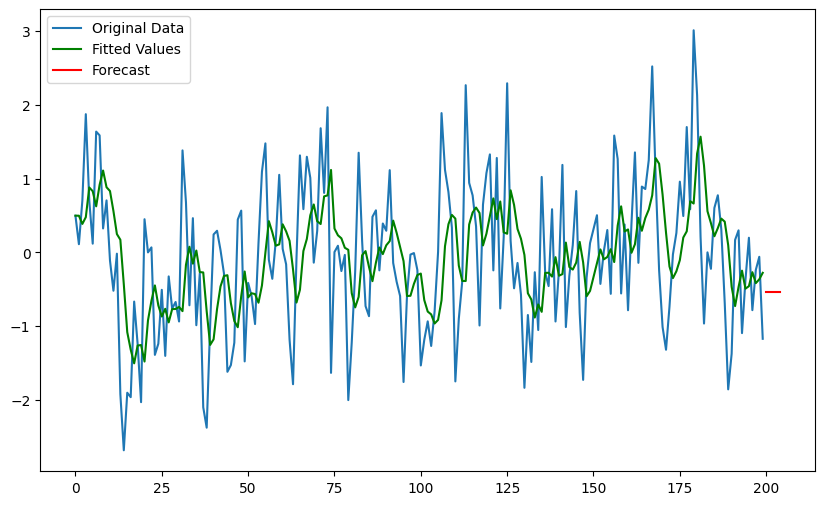

In [18]:
plt.figure(figsize=(10,6))
plt.plot(df['0'], label = 'Original Data')
plt.plot(model_fitted.fittedvalues, label='Fitted Values', color='green')
plt.plot(range(len(df), len(df)+5), forecast, label='Forecast', color='red')
plt.legend()
plt.show()

filure for future predections but got trained correctly

### holts linear

In [19]:
model = ExponentialSmoothing(df['0'], trend = 'add', seasonal=None)
# model_fitted = model.fit(smoothing_level=0.8, smoothing_slope=0.2, optimized=False)
model_fitted = model.fit(optimized=True)

In [20]:
rmse = np.sqrt(np.mean(model_fitted.resid**2))
display(rmse)

1.002277186889522

In [21]:
# next 5 periods ==> h = 5
forecast = model_fitted.forecast(steps = 5)
print("Fitted value: ", model_fitted.fittedvalues)
print("Forecasted values:", forecast)

Fitted value:  0      0.629035
1      0.585312
2      0.443640
3      0.511725
4      0.895049
         ...   
195   -0.478496
196   -0.291251
197   -0.438211
198   -0.387165
199   -0.299971
Length: 200, dtype: float64
Forecasted values: 200   -0.555437
201   -0.561362
202   -0.567288
203   -0.573213
204   -0.579138
dtype: float64


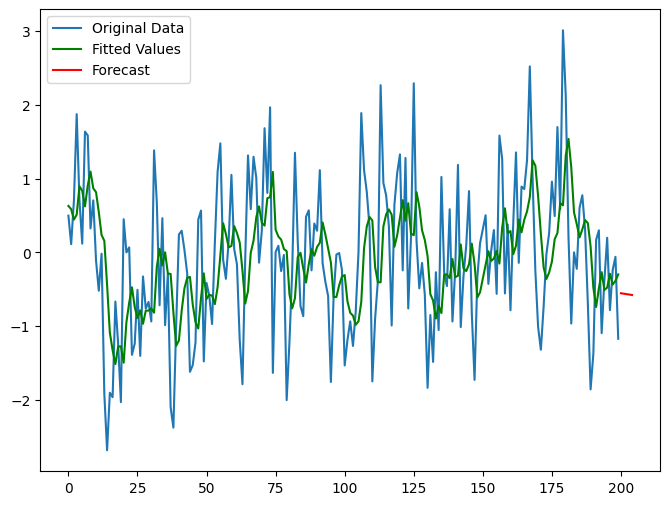

In [22]:
plt.figure(figsize=(8,6))
plt.plot(df['0'], label = 'Original Data')
plt.plot(model_fitted.fittedvalues, label='Fitted Values', color='green')
plt.plot(range(len(df), len(df)+5), forecast, label='Forecast', color='red')
plt.legend()
plt.show()

not good at past values observation but adjusted the future values  
so not good but rmse is better than SMS

### holt seasonal

In [23]:
model = ExponentialSmoothing(df['0'], trend = 'add', seasonal='add', seasonal_periods=6)
# model_fitted = model.fit(smoothing_level=0.8, smoothing_slope=0.2, optimized=False)
model_fitted = model.fit(optimized=True)

In [24]:
rmse = np.sqrt(np.mean(model_fitted.resid**2))
display(rmse)

0.9511266690819291

In [27]:
# next 5 periods ==> h = 5
forecast = model_fitted.forecast(steps = 10)
print("Fitted value: ", model_fitted.fittedvalues)
print("Forecasted values:", forecast)

Fitted value:  0      0.913187
1      0.390779
2     -0.087649
3      0.374260
4      0.955803
         ...   
195   -0.621696
196   -0.278528
197    0.037342
198   -0.074704
199   -0.446527
Length: 200, dtype: float64
Forecasted values: 200   -1.081262
201   -0.896142
202   -0.839941
203   -0.346712
204   -0.362066
205   -0.738628
206   -1.118760
207   -0.933640
208   -0.877438
209   -0.384210
dtype: float64


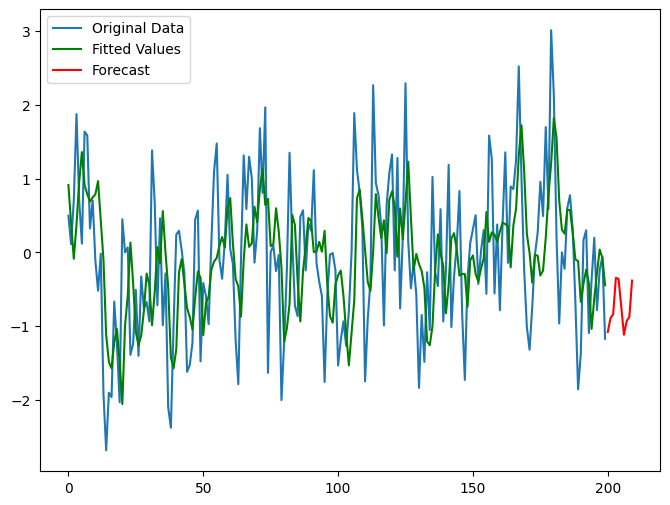

In [29]:
plt.figure(figsize=(8,6))
plt.plot(df['0'], label = 'Original Data')
plt.plot(model_fitted.fittedvalues, label='Fitted Values', color='green')
plt.plot(range(len(df), len(df)+10), forecast, label='Forecast', color='red')
plt.legend()
plt.show()